# NSL-KDD — Exploratory Data Analysis

Visual EDA for binary intrusion detection (normal vs attack) on `KDDTrain+` / `KDDTest+`.
Each section has three short notes:

- **Observation:** what the data shows.
- **Interpretation:** what it means.
- **Decision:** what preprocessing does about it.

Every decision is applied later inside a scikit-learn pipeline that is fit on training data only. No row is removed here. Figures are saved to `docs/images/eda/` and embedded in `docs/dataset_notes.md`.

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.config import load_config, set_all_seeds
from src.data_loader import load_nsl_kdd, FEATURE_COLUMNS, FEATURE_GROUPS

CFG = load_config()
SEED = CFG["seed"]
rng = set_all_seeds(SEED)

FIG_DIR = PROJECT_ROOT / "docs" / "images" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_ROOT / "results" / "eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY = {}

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 120, "savefig.bbox": "tight"})
PAL = {"normal": "#4C72B0", "attack": "#DD8452"}

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

# Headered copies produced by dataset/add_headers.py
train, test = load_nsl_kdd(PROJECT_ROOT / "dataset" / "KDDTrain+.csv",
                           PROJECT_ROOT / "dataset" / "KDDTest+.csv")
CAT = ["protocol_type", "service", "flag"]
NUM = [c for c in FEATURE_COLUMNS if c not in CAT]
GROUP_OF = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}
for df in (train, test):
    df["target"] = np.where(df["is_intrusion"] == 1, "attack", "normal")
print(train.shape, test.shape)

(125973, 46) (22543, 46)


## 1. Basic structure and schema consistency

In [2]:
def structure(df, name):
    return {"split": name, "rows": len(df), "columns": 43,
            "memory_MB": round(df[FEATURE_COLUMNS + ["label", "difficulty_level"]].memory_usage(deep=True).sum() / 2**20, 1),
            "numeric": len(df[FEATURE_COLUMNS].select_dtypes("number").columns),
            "categorical": len(df[FEATURE_COLUMNS].select_dtypes(exclude="number").columns)}

struct = pd.DataFrame([structure(train, "train"), structure(test, "test")]).set_index("split")
same_cols = list(train.columns) == list(test.columns)
same_dtypes = (train[FEATURE_COLUMNS].dtypes.astype(str) == test[FEATURE_COLUMNS].dtypes.astype(str)).all()
# numeric values stored as text? try coercing each non-numeric feature column
num_as_str = [c for c in train[FEATURE_COLUMNS].select_dtypes(exclude="number")
              if pd.to_numeric(train[c], errors="coerce").notna().mean() > 0.5]
SUMMARY["structure"] = {"train_rows": len(train), "test_rows": len(test),
                        "same_columns": same_cols, "same_dtypes": bool(same_dtypes),
                        "numeric_stored_as_string": num_as_str}
display(struct)
print("schema identical:", same_cols, "| dtypes identical:", bool(same_dtypes), "| numeric-as-string:", num_as_str or "none")

,rows,columns,memory_MB,numeric,categorical
split,,,,,
train,125973,43,43.4,38,3
test,22543,43,7.8,38,3


schema identical: True | dtypes identical: True | numeric-as-string: none


**Observation:** Both files have the same 43 columns and dtypes: 38 numeric and 3 categorical features. No numeric column is stored as text.
**Decision:** No type conversion is needed. The column lists are fixed in `src/features.py`, so selection does not depend on dtype inference.

## 2. Data quality

In [3]:
num_tr = train[NUM]
quality = {
    "missing_train": int(train[FEATURE_COLUMNS].isna().sum().sum()),
    "missing_test": int(test[FEATURE_COLUMNS].isna().sum().sum()),
    "inf_train": int(np.isinf(num_tr.to_numpy(dtype=float)).sum()),
    "inf_test": int(np.isinf(test[NUM].to_numpy(dtype=float)).sum()),
    "dup_rows_train": int(train[FEATURE_COLUMNS + ["label"]].duplicated().sum()),
    "dup_rows_test": int(test[FEATURE_COLUMNS + ["label"]].duplicated().sum()),
    "dup_features_train": int(train[FEATURE_COLUMNS].duplicated().sum()),
}
# identical feature vectors carrying different binary labels (irreducible error)
g = train.groupby(FEATURE_COLUMNS, observed=True)["is_intrusion"].nunique()
quality["conflicting_feature_vectors_train"] = int((g > 1).sum())
# train/test overlap on features
overlap = train[FEATURE_COLUMNS].drop_duplicates().merge(test[FEATURE_COLUMNS].drop_duplicates(), how="inner")
quality["train_test_feature_overlap"] = len(overlap)

rate_cols = [c for c in NUM if c.endswith("_rate")]
binary_cols = ["land", "logged_in", "root_shell", "su_attempted", "is_host_login", "is_guest_login"]
quality["rates_outside_0_1"] = int(((train[rate_cols] < 0) | (train[rate_cols] > 1)).sum().sum())
quality["negative_values"] = int((num_tr < 0).sum().sum())
quality["binary_outside_0_1"] = {c: int((~train[c].isin([0, 1])).sum()) for c in binary_cols if (~train[c].isin([0, 1])).any()}
SUMMARY["quality"] = quality
pd.Series({k: v for k, v in quality.items()}).to_frame("value")

,value
missing_train,0
missing_test,0
inf_train,0
inf_test,0
dup_rows_train,0
dup_rows_test,0
dup_features_train,16
conflicting_feature_vectors_train,7
train_test_feature_overlap,654
rates_outside_0_1,0


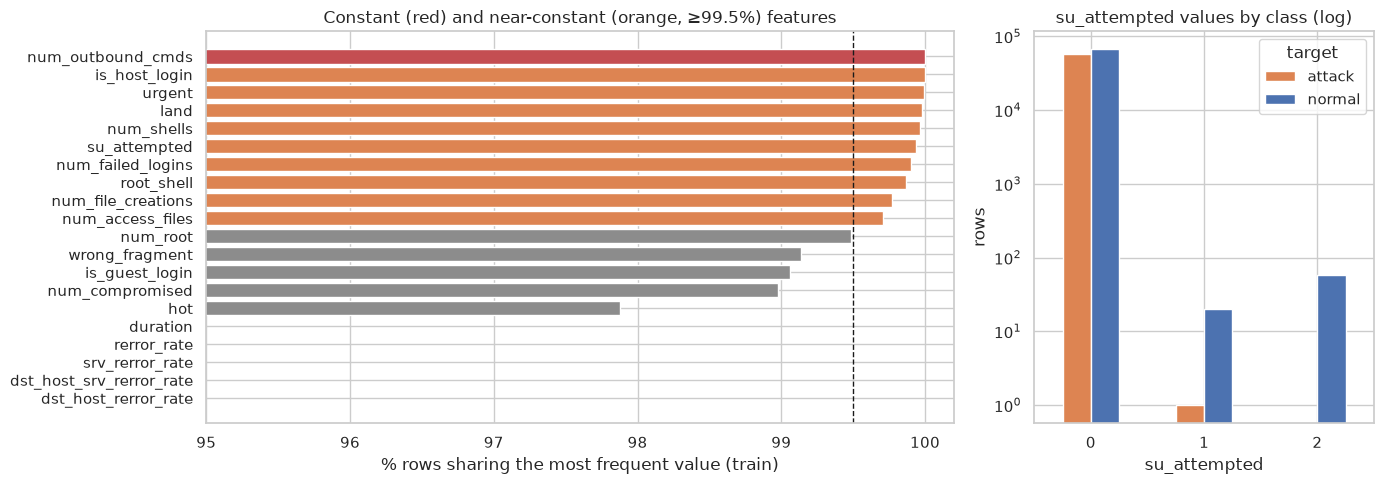

su_attempted=2 rows, root_shell share: 1.0 | attack share: 0.0


In [4]:
# Constant / near-constant features: share of the most frequent value
dom = pd.Series({c: train[c].value_counts(normalize=True).iloc[0] for c in FEATURE_COLUMNS}).sort_values(ascending=False)
near_const = dom[dom >= 0.995]
SUMMARY["constant"] = dom[dom == 1.0].index.tolist()
SUMMARY["near_constant_0.995"] = near_const.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2.2, 1]})
top = dom.head(20)
axes[0].barh(top.index[::-1], top.values[::-1] * 100,
             color=["#C44E52" if v == 1 else "#DD8452" if v >= 0.995 else "#8C8C8C" for v in top.values[::-1]])
axes[0].axvline(99.5, ls="--", c="k", lw=1)
axes[0].set_xlim(95, 100.2); axes[0].set_xlabel("% rows sharing the most frequent value (train)")
axes[0].set_title("Constant (red) and near-constant (orange, ≥99.5%) features")

# su_attempted = 2: how does it co-occur with labels and root_shell?
su = pd.crosstab(train["su_attempted"], train["target"])
su.plot(kind="bar", ax=axes[1], color=[PAL["attack"], PAL["normal"]], logy=True, rot=0)
axes[1].set_title("su_attempted values by class (log)"); axes[1].set_ylabel("rows")
fig.tight_layout(); save(fig, "01_quality_near_constant")
print("su_attempted=2 rows, root_shell share:", train.loc[train.su_attempted == 2, "root_shell"].mean().round(3),
      "| attack share:", train.loc[train.su_attempted == 2, "is_intrusion"].mean().round(3))
SUMMARY["su_attempted_2"] = {"train": int((train.su_attempted == 2).sum()), "test": int((test.su_attempted == 2).sum()),
                             "attack_share": float(train.loc[train.su_attempted == 2, "is_intrusion"].mean()),
                             "root_shell_share": float(train.loc[train.su_attempted == 2, "root_shell"].mean())}

**Observation:** There are no missing, infinite or negative values, no out-of-range rates, and no exact duplicate rows. `num_outbound_cmds` is constant. Several content flags are near-constant: `land`, `urgent`, `num_shells`, `is_host_login`, `root_shell` and others. `su_attempted` takes the value **2**, which is outside its binary definition. All 59 train rows with value 2 are *normal*, and all have `root_shell = 1`. 16 train feature vectors are repeated, and 7 of them carry conflicting labels. 654 distinct feature vectors appear in both train and test.

**Interpretation:** No imputation is needed, and there are no division-by-zero artefacts. Near-constant content flags are rare but are exactly the U2R/R2L signatures, so a variance filter would discard real attack evidence. `su_attempted = 2` behaves like "attempted", so it is a coding artefact, not a third state.

**Decision:**
- Drop `num_outbound_cmds`.
- Keep the near-constant flags; regularisation and trees can ignore them.
- Map `su_attempted` 2 → 1. This is row-wise and label-free, so it cannot leak.
- Remove no rows: there are no duplicates, and conflicting vectors are part of the irreducible error.

## 3. Target and class balance

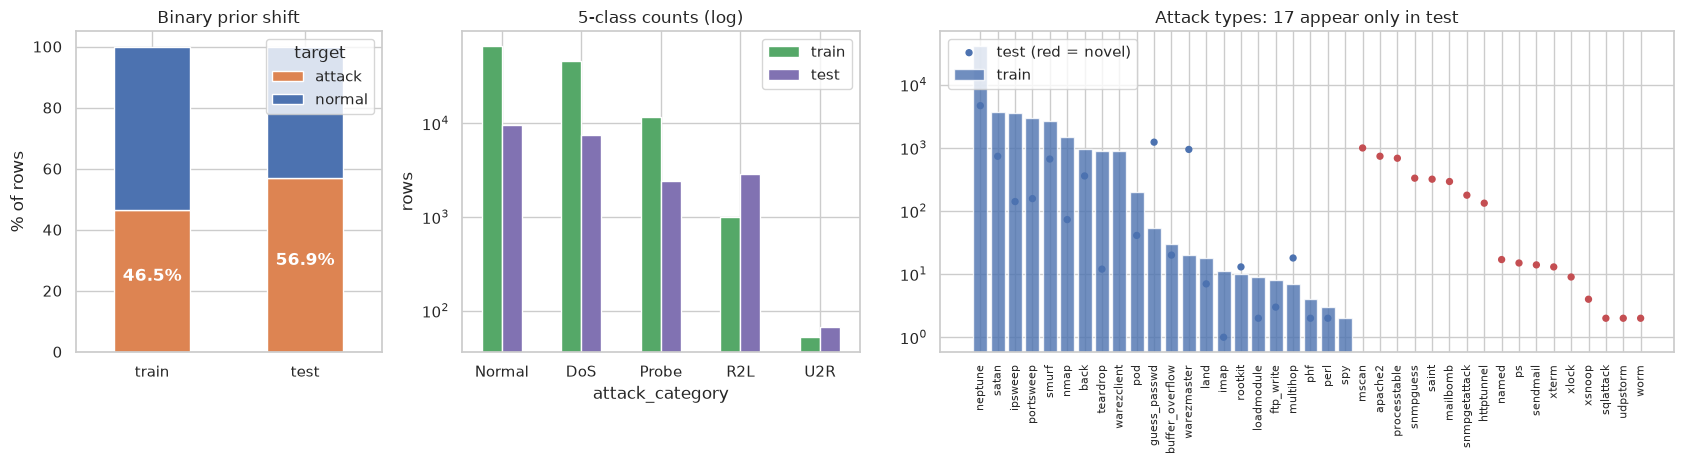

{'train_attack_pct': np.float64(46.54),
 'test_attack_pct': np.float64(56.93),
 'train_5class': {'Normal': 67343,
  'DoS': 45927,
  'Probe': 11656,
  'R2L': 995,
  'U2R': 52},
 'test_5class': {'Normal': 9710,
  'DoS': 7458,
  'R2L': 2887,
  'Probe': 2421,
  'U2R': 67},
 'novel_attack_types': ['apache2',
  'httptunnel',
  'mailbomb',
  'mscan',
  'named',
  'processtable',
  'ps',
  'saint',
  'sendmail',
  'snmpgetattack',
  'snmpguess',
  'sqlattack',
  'udpstorm',
  'worm',
  'xlock',
  'xsnoop',
  'xterm'],
 'novel_rows_test': 3750,
 'novel_share_of_test_attacks_pct': np.float64(29.22),
 'attack_types_lt_20_train': 9}

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.3, 2.4]})
b = pd.DataFrame({"train": train.target.value_counts(normalize=True), "test": test.target.value_counts(normalize=True)}) * 100
b.T.plot(kind="bar", stacked=True, ax=axes[0], color=[PAL["attack"], PAL["normal"]], rot=0)
axes[0].set_ylabel("% of rows"); axes[0].set_title("Binary prior shift")
for i, s in enumerate(["train", "test"]):
    axes[0].text(i, b.loc["attack", s] / 2, f"{b.loc['attack', s]:.1f}%", ha="center", c="white", weight="bold")

order = ["Normal", "DoS", "Probe", "R2L", "U2R"]
c5 = pd.DataFrame({"train": train.attack_category.value_counts(), "test": test.attack_category.value_counts()}).reindex(order)
c5.plot(kind="bar", ax=axes[1], logy=True, rot=0, color=["#55A868", "#8172B2"])
axes[1].set_title("5-class counts (log)"); axes[1].set_ylabel("rows")

novel = sorted(set(test.label) - set(train.label))
lab = pd.DataFrame({"train": train.label.value_counts(), "test": test.label.value_counts()}).fillna(0).drop("normal")
lab = lab.sort_values(["train", "test"], ascending=False)
colors = ["#C44E52" if l in novel else "#4C72B0" for l in lab.index]
axes[2].bar(range(len(lab)), lab["train"].replace(0, np.nan), color="#4C72B0", alpha=.8, label="train")
axes[2].scatter(range(len(lab)), lab["test"].replace(0, np.nan), c=colors, s=18, zorder=3, label="test (red = novel)")
axes[2].set_yscale("log"); axes[2].set_xticks(range(len(lab))); axes[2].set_xticklabels(lab.index, rotation=90, fontsize=8)
axes[2].set_title(f"Attack types: {len(novel)} appear only in test"); axes[2].legend()
fig.tight_layout(); save(fig, "02_class_balance")

SUMMARY["target"] = {
    "train_attack_pct": round(train.is_intrusion.mean() * 100, 2), "test_attack_pct": round(test.is_intrusion.mean() * 100, 2),
    "train_5class": train.attack_category.value_counts().to_dict(), "test_5class": test.attack_category.value_counts().to_dict(),
    "novel_attack_types": novel, "novel_rows_test": int(test.label.isin(novel).sum()),
    "novel_share_of_test_attacks_pct": round(test.label.isin(novel).sum() / test.is_intrusion.sum() * 100, 2),
    "attack_types_lt_20_train": int((train.label.value_counts() < 20).sum()),
}
SUMMARY["target"]

**Observation:** The binary task is roughly balanced in train: 46.5% attack. Test is 56.9% attack, which is **prior shift**. Within attacks, DoS dominates train. R2L and U2R are tiny in train, but R2L is large in test. 17 attack types (including most R2L/U2R test traffic) appear **only in test**.

**Interpretation:** At the binary level, imbalance is mild; the real difficulty is generalising to unseen attack families. Accuracy rewards guessing "attack" under the test prior, so macro-F1, PR-AUC, recall and FPR are reported instead.

**Decision:**
- Binary target `is_intrusion`. No rare-class removal or merging is needed for the binary task; the 39 attack names collapse to "attack".
- `class_weight` is tuned as {None, balanced}. No SMOTE: the binary ratio is near 50/50, and synthetic minority points would not represent the novel test families.
- Test stays untouched with its original distribution.

## 4. Feature distributions, skew and outliers

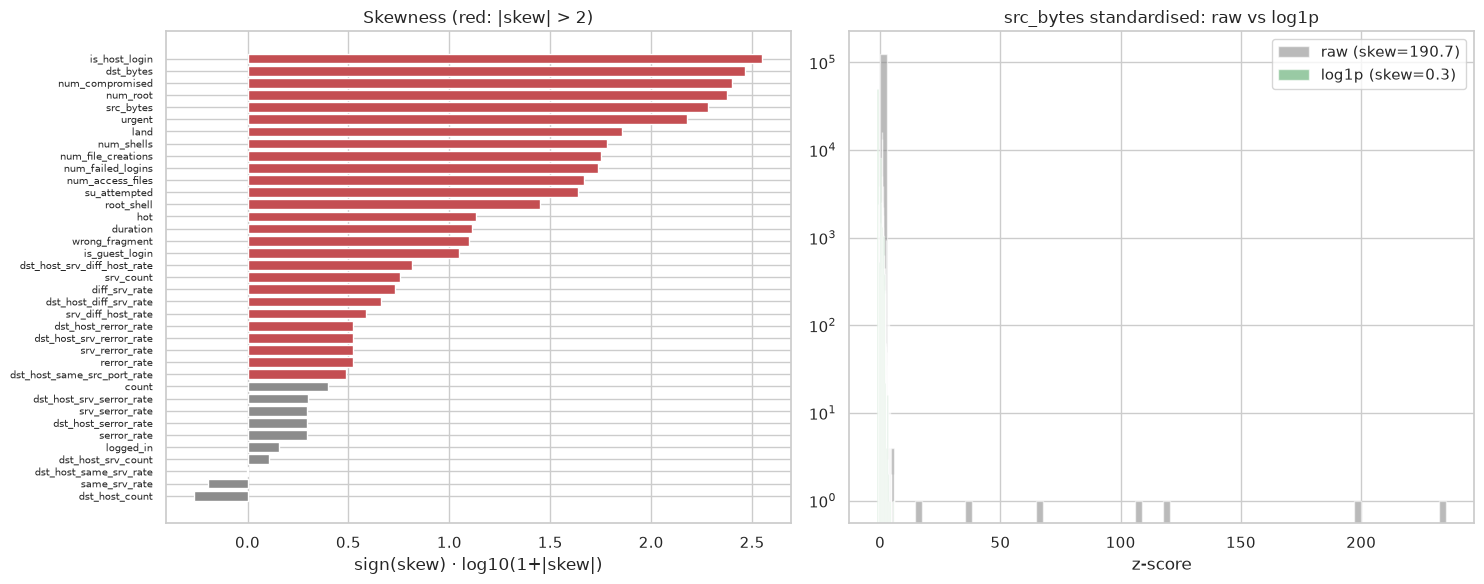

In [6]:
skew = train[NUM].skew().drop("num_outbound_cmds").sort_values(ascending=False)
heavy = skew[skew.abs() > 2].index.tolist()
SUMMARY["skew_top"] = skew.head(10).round(1).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cols = ["#C44E52" if c in heavy else "#8C8C8C" for c in skew.index]
axes[0].barh(skew.index[::-1], np.sign(skew.values[::-1]) * np.log10(1 + np.abs(skew.values[::-1])), color=cols[::-1])
axes[0].set_xlabel("sign(skew) · log10(1+|skew|)"); axes[0].set_title("Skewness (red: |skew| > 2)")
axes[0].tick_params(axis="y", labelsize=7)

# Effect of log1p on the most skewed count/byte feature
for c, col in [("raw", "#8C8C8C"), ("log1p", "#55A868")]:
    vals = train["src_bytes"] if c == "raw" else np.log1p(train["src_bytes"])
    axes[1].hist((vals - vals.mean()) / vals.std(), bins=80, alpha=.6, color=col, label=f"{c} (skew={vals.skew():.1f})", log=True)
axes[1].set_title("src_bytes standardised: raw vs log1p"); axes[1].legend(); axes[1].set_xlabel("z-score")
fig.tight_layout(); save(fig, "03_skewness")

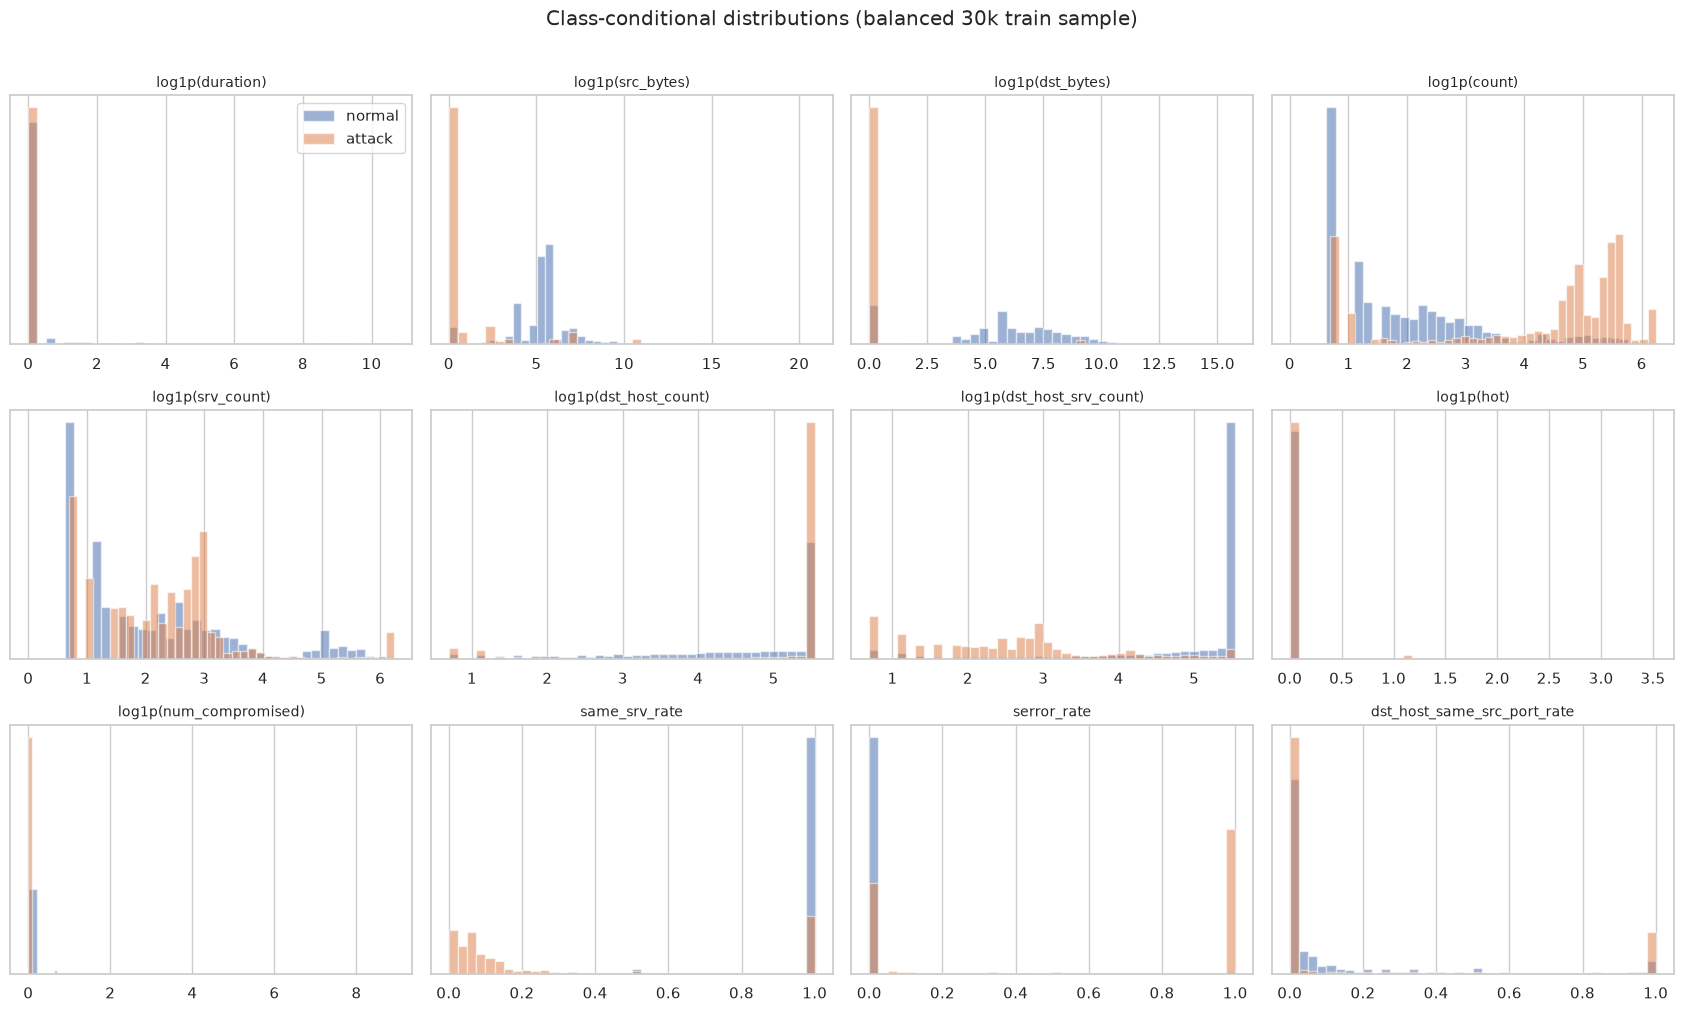

In [7]:
key = ["duration", "src_bytes", "dst_bytes", "count", "srv_count", "dst_host_count",
       "dst_host_srv_count", "hot", "num_compromised", "same_srv_rate", "serror_rate", "dst_host_same_src_port_rate"]
sample = train.groupby("target", group_keys=False).sample(n=15000, random_state=SEED)
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, c in zip(axes.ravel(), key):
    rate = c.endswith("_rate")
    data = sample[c] if rate else np.log1p(sample[c])
    for t in ["normal", "attack"]:
        ax.hist(data[sample.target == t], bins=40, alpha=.55, color=PAL[t], label=t, density=True)
    ax.set_title(c if rate else f"log1p({c})", fontsize=10); ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Class-conditional distributions (balanced 30k train sample)", y=1.01)
fig.tight_layout(); save(fig, "04_class_conditional_distributions")

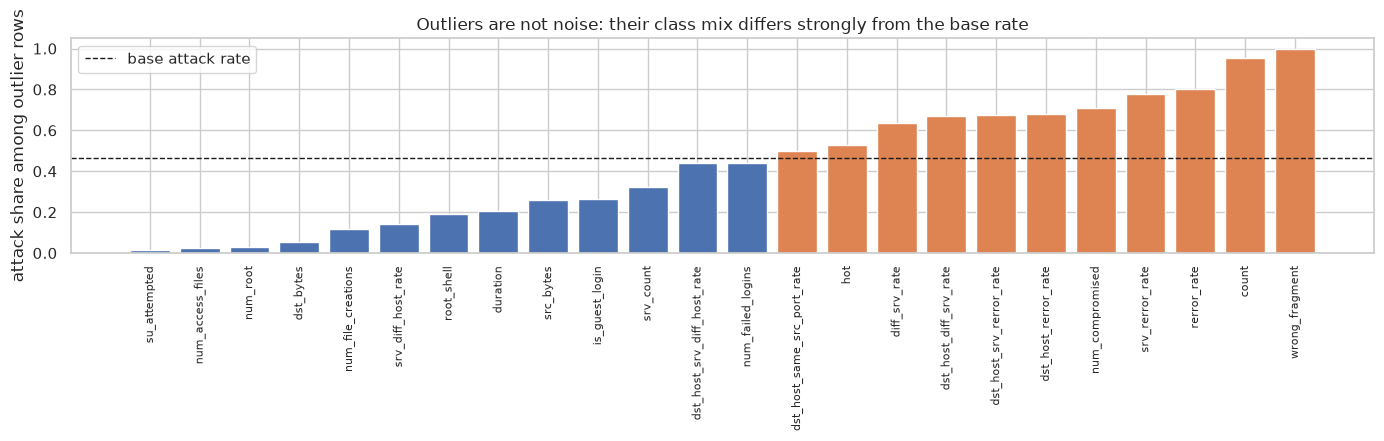

In [8]:
# Are IQR outliers data errors or attack behaviour? Attack share among outlier rows vs base rate.
out = {}
for c in [c for c in NUM if c != "num_outbound_cmds"]:
    q1, q3 = train[c].quantile([.25, .75]); iqr = q3 - q1
    if iqr == 0:  # zero-inflated: any non-mode value counts as outlier
        mask = train[c] != train[c].mode()[0]
    else:
        mask = (train[c] < q1 - 1.5 * iqr) | (train[c] > q3 + 1.5 * iqr)
    if mask.sum() >= 50:
        out[c] = {"outlier_pct": mask.mean() * 100, "attack_share": train.loc[mask, "is_intrusion"].mean()}
out = pd.DataFrame(out).T.sort_values("attack_share")
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(out.index, out["attack_share"], color=np.where(out["attack_share"] > train.is_intrusion.mean(), PAL["attack"], PAL["normal"]))
ax.axhline(train.is_intrusion.mean(), ls="--", c="k", lw=1, label="base attack rate")
ax.set_ylabel("attack share among outlier rows"); ax.set_title("Outliers are not noise: their class mix differs strongly from the base rate")
ax.tick_params(axis="x", rotation=90, labelsize=8); ax.legend()
fig.tight_layout(); save(fig, "05_outliers_vs_attacks")
SUMMARY["outlier_features_attack_enriched"] = int((out.attack_share > train.is_intrusion.mean()).sum())
SUMMARY["outlier_features_total"] = len(out)

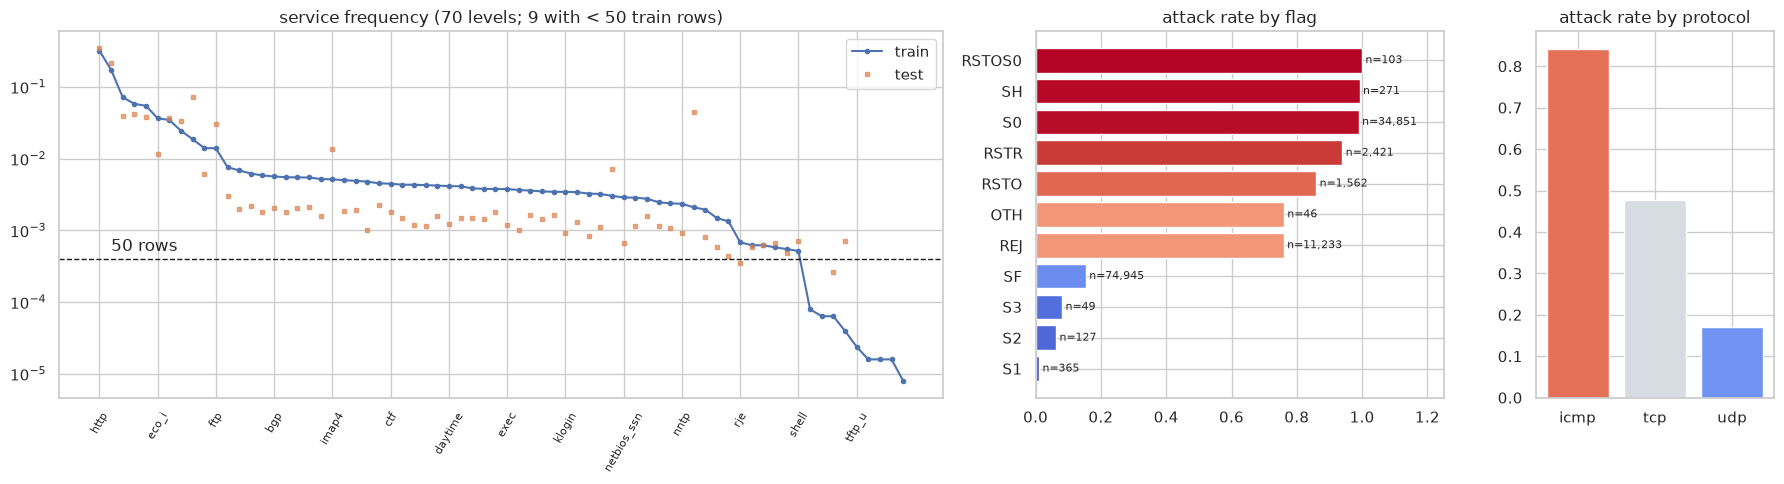

unseen test categories: {'protocol_type': [], 'service': [], 'flag': []}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [2.6, 1.2, .7]})
svc = pd.DataFrame({"train": train.service.value_counts(normalize=True), "test": test.service.value_counts(normalize=True)}).fillna(0)
svc = svc.sort_values("train", ascending=False)
axes[0].plot(range(len(svc)), svc["train"], "o-", ms=3, label="train"); axes[0].plot(range(len(svc)), svc["test"], "s", ms=3, alpha=.7, label="test")
axes[0].set_yscale("log"); axes[0].set_title(f"service frequency (70 levels; {int((train.service.value_counts() < 50).sum())} with < 50 train rows)")
axes[0].axhline(50 / len(train), ls="--", c="k", lw=1); axes[0].text(1, 50 / len(train) * 1.3, "50 rows")
axes[0].set_xticks(range(0, len(svc), 5)); axes[0].set_xticklabels(svc.index[::5], rotation=60, fontsize=8); axes[0].legend()

fl = train.groupby("flag")["is_intrusion"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh(fl.index, fl["mean"], color=plt.cm.coolwarm(fl["mean"]))
for i, (m, n) in enumerate(zip(fl["mean"], fl["size"])): axes[1].text(m + .01, i, f"n={n:,}", va="center", fontsize=8)
axes[1].set_xlim(0, 1.25); axes[1].set_title("attack rate by flag")
pr = train.groupby("protocol_type")["is_intrusion"].mean()
axes[2].bar(pr.index, pr.values, color=plt.cm.coolwarm(pr.values)); axes[2].set_title("attack rate by protocol")
fig.tight_layout(); save(fig, "06_categorical")
unseen = {c: sorted(set(test[c]) - set(train[c])) for c in CAT}
SUMMARY["categorical"] = {"cardinality_train": {c: int(train[c].nunique()) for c in CAT},
                          "unseen_test_levels": unseen,
                          "train_only_services": sorted(set(train.service) - set(test.service)),
                          "services_lt_50_rows": int((train.service.value_counts() < 50).sum())}
print("unseen test categories:", unseen)

**Observation:**
- Counts and bytes are zero-inflated and extremely right-skewed (`src_bytes`, `dst_bytes`, `duration`, `num_compromised`, …). `log1p` reduces this skew by orders of magnitude.
- Rates are bounded in [0, 1] and bimodal.
- Outliers carry a class mix very different from the base rate. In 11 of 24 features they are attack-enriched; in the rest they are normal-enriched. Either way they are informative.
- `service` has 70 levels with a long tail, and 9 levels have fewer than 50 train rows. Test introduces **no unseen categories**.
- `flag` and `protocol_type` are strongly class-dependent: S0/REJ/RSTR are almost all attacks.

**Interpretation:** Extreme values are attack signatures, not errors. Linear models need the tails compressed; trees do not care about monotone transforms.

**Decision:**
- `log1p` → `StandardScaler` for heavy-tailed counts/bytes, and `StandardScaler` for rates, in the linear model only.
- No outlier removal or clipping.
- One-hot encode the three categoricals. Group rare `service` levels with `min_frequency=50` into an "infrequent" bucket, and use `handle_unknown="infrequent_if_exist"` defensively.

## 5. Feature–target relationships and leakage

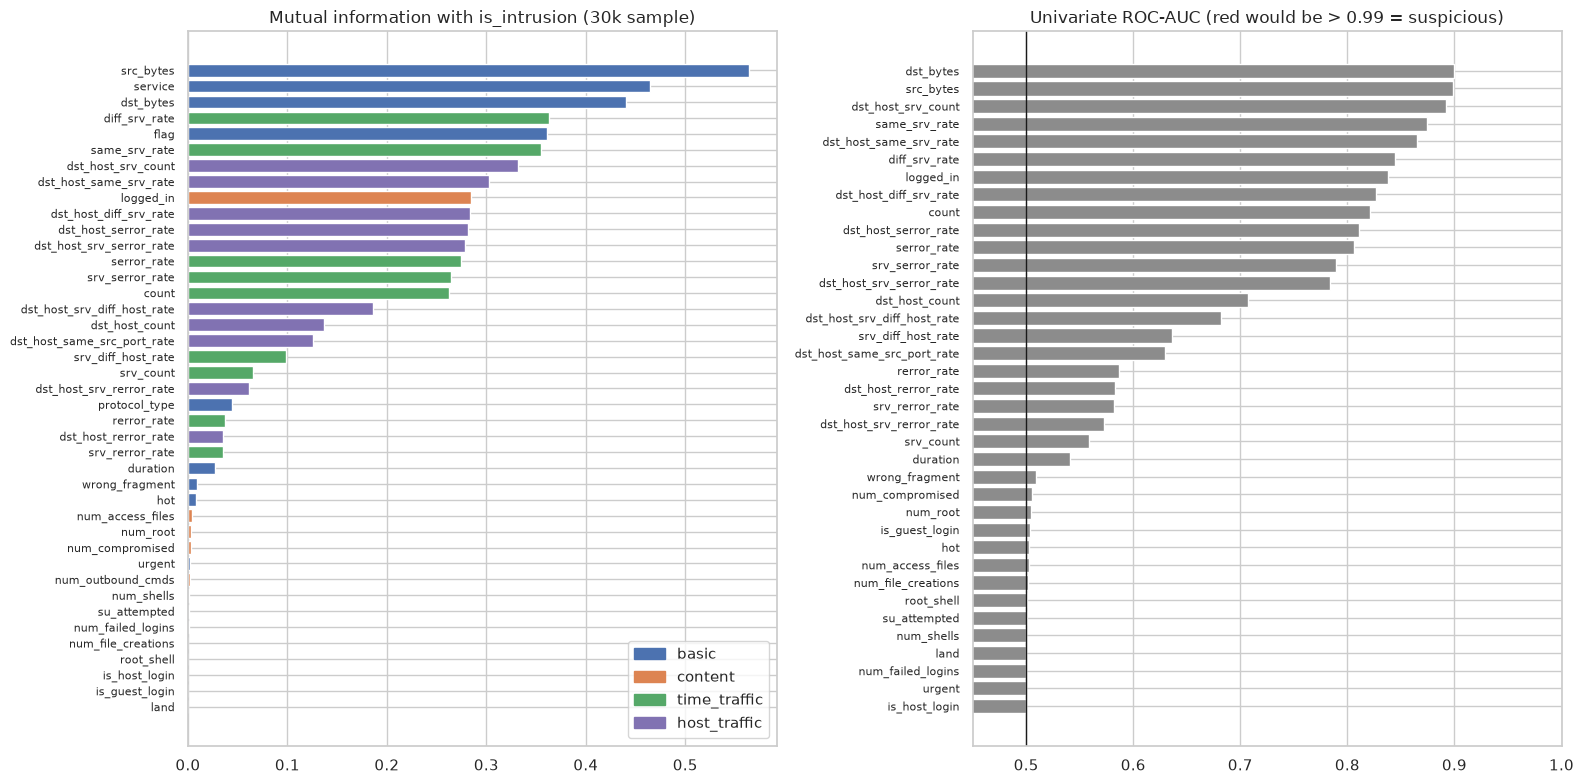

In [10]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

mi_s = train.sample(n=CFG["selection"]["mi_sample_size"], random_state=SEED)
X_mi = mi_s[FEATURE_COLUMNS].copy()
for c in CAT: X_mi[c] = X_mi[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(X_mi, mi_s.is_intrusion, discrete_features=[c in CAT for c in FEATURE_COLUMNS],
                                   random_state=SEED), index=FEATURE_COLUMNS).sort_values()
# Univariate ROC-AUC (direction-free) to flag suspiciously perfect separation
auc = pd.Series({c: max(roc_auc_score(train.is_intrusion, train[c]), 1 - roc_auc_score(train.is_intrusion, train[c]))
                 for c in NUM if train[c].nunique() > 1})
SUMMARY["mi_top10"] = mi.sort_values(ascending=False).head(10).round(3).to_dict()
SUMMARY["mi_zero"] = mi[mi < 0.001].index.tolist()
SUMMARY["max_univariate_auc"] = {"feature": auc.idxmax(), "auc": round(float(auc.max()), 3)}

grp_col = {"basic": "#4C72B0", "content": "#DD8452", "time_traffic": "#55A868", "host_traffic": "#8172B2"}
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].barh(mi.index, mi.values, color=[grp_col[GROUP_OF[c]] for c in mi.index])
axes[0].set_title("Mutual information with is_intrusion (30k sample)"); axes[0].tick_params(axis="y", labelsize=8)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in grp_col.items()], loc="lower right")
a = auc.sort_values()
axes[1].barh(a.index, a.values, color=np.where(a.values > .99, "#C44E52", "#8C8C8C"))
axes[1].axvline(.5, c="k", lw=1); axes[1].set_xlim(.45, 1); axes[1].set_title("Univariate ROC-AUC (red would be > 0.99 = suspicious)")
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout(); save(fig, "07_feature_target_mi_auc")

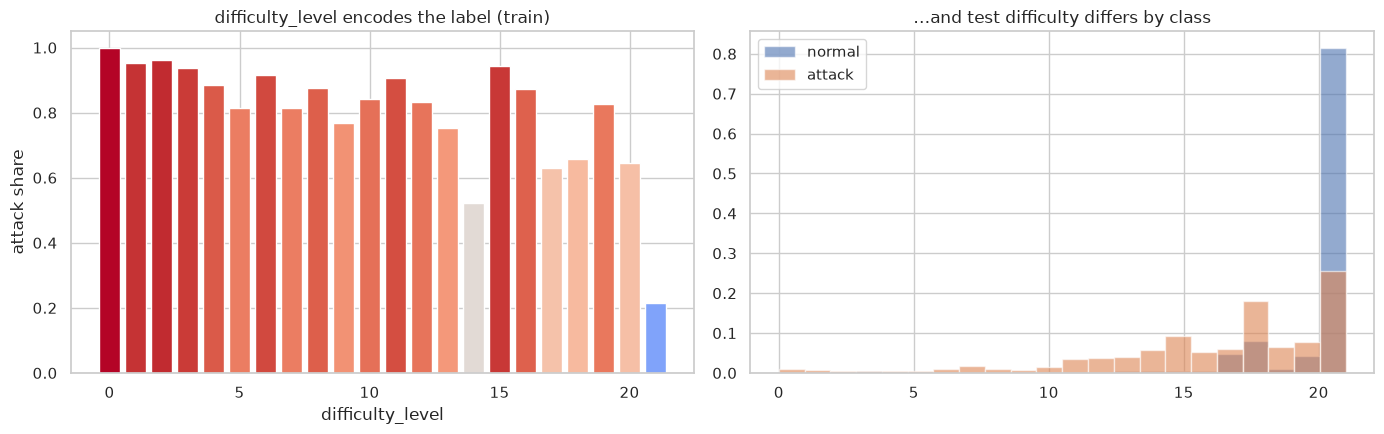

difficulty_level univariate AUC: 0.763


In [11]:
# difficulty_level: computed from classifier agreement with the TRUE label -> leakage
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dl = pd.crosstab(train.difficulty_level, train.target, normalize="index")["attack"]
axes[0].bar(dl.index, dl.values, color=plt.cm.coolwarm(dl.values)); axes[0].set_xlabel("difficulty_level")
axes[0].set_ylabel("attack share"); axes[0].set_title("difficulty_level encodes the label (train)")
for t in ["normal", "attack"]:
    axes[1].hist(test.loc[test.target == t, "difficulty_level"], bins=22, alpha=.6, color=PAL[t], label=t, density=True)
axes[1].set_title("…and test difficulty differs by class"); axes[1].legend()
fig.tight_layout(); save(fig, "08_difficulty_leakage")
SUMMARY["difficulty_auc_train"] = round(float(max(roc_auc_score(train.is_intrusion, train.difficulty_level),
                                                1 - roc_auc_score(train.is_intrusion, train.difficulty_level))), 3)
print("difficulty_level univariate AUC:", SUMMARY["difficulty_auc_train"])

**Observation:**
- The most informative features are traffic-volume and service-pattern features: `src_bytes`, `service`, `dst_bytes`, `flag`, `same_srv_rate`, `diff_srv_rate`, and the `dst_host_*` rates.
- Content flags have near-zero MI at the binary level.
- No single numeric feature separates the classes perfectly (max univariate AUC < 0.99), so there is no obvious leakage among the 41 features.
- The dataset has **no IP, port, timestamp or flow-ID columns**.
- `difficulty_level` varies systematically with the label.

**Interpretation:** The signal is spread over many correlated traffic features. `difficulty_level` is derived from the label (agreement of 21 learners), so it is leakage.

**Decision:**
- `difficulty_level`, `label`/`class` and all derived targets are excluded from `X`. `difficulty_level` is used only for evaluation slices.
- Low-MI content flags are kept, because they matter for rare R2L/U2R attacks.
- Feature selection is left to regularisation (LR) and to the tree's own splits, not to a hand-picked MI cut.

## 6. Feature relationships and class separability

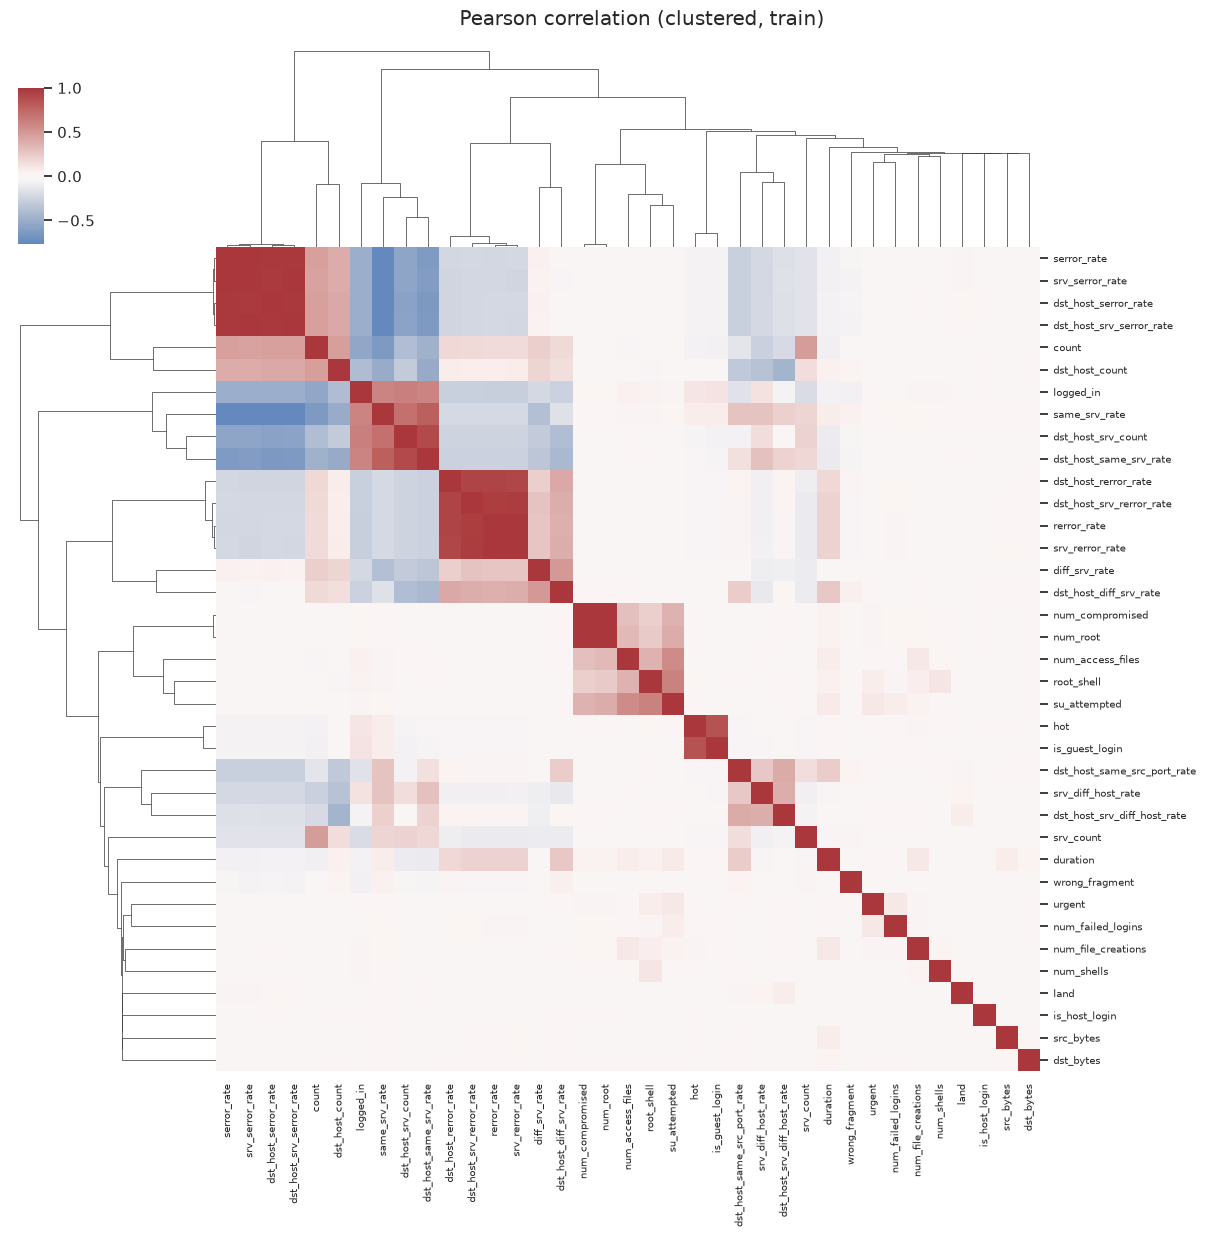

,level_0,level_1,r
345,num_compromised,num_root,0.9988
761,serror_rate,srv_serror_rate,0.9933
837,rerror_rate,srv_rerror_rate,0.9890
811,srv_serror_rate,dst_host_srv_serror_rate,0.9863
1255,dst_host_serror_rate,dst_host_srv_serror_rate,0.9851
774,serror_rate,dst_host_srv_serror_rate,0.9811
773,serror_rate,dst_host_serror_rate,0.9794
810,srv_serror_rate,dst_host_serror_rate,0.9776
887,srv_rerror_rate,dst_host_srv_rerror_rate,0.9702
850,rerror_rate,dst_host_srv_rerror_rate,0.9644


In [12]:
num_active = [c for c in NUM if c not in SUMMARY["constant"]]
corr = train[num_active].corr()
fig = sns.clustermap(corr, cmap="vlag", center=0, figsize=(13, 13), xticklabels=True, yticklabels=True,
                     cbar_pos=(0.02, 0.83, 0.02, 0.12), method="average")
fig.ax_heatmap.tick_params(labelsize=7); fig.fig.suptitle("Pearson correlation (clustered, train)", y=1.01)
fig.savefig(FIG_DIR / "09_correlation_clustermap.png"); plt.show()

iu = np.triu(np.ones_like(corr, dtype=bool), 1)
pairs = corr.where(iu).stack().rename("r").reset_index()
pairs = pairs[pairs.r.abs() > 0.95].sort_values("r", key=abs, ascending=False)
SUMMARY["corr_pairs_gt_0.95"] = [(a, b, round(r, 4)) for a, b, r in pairs.itertuples(index=False)]
pairs.round(4)

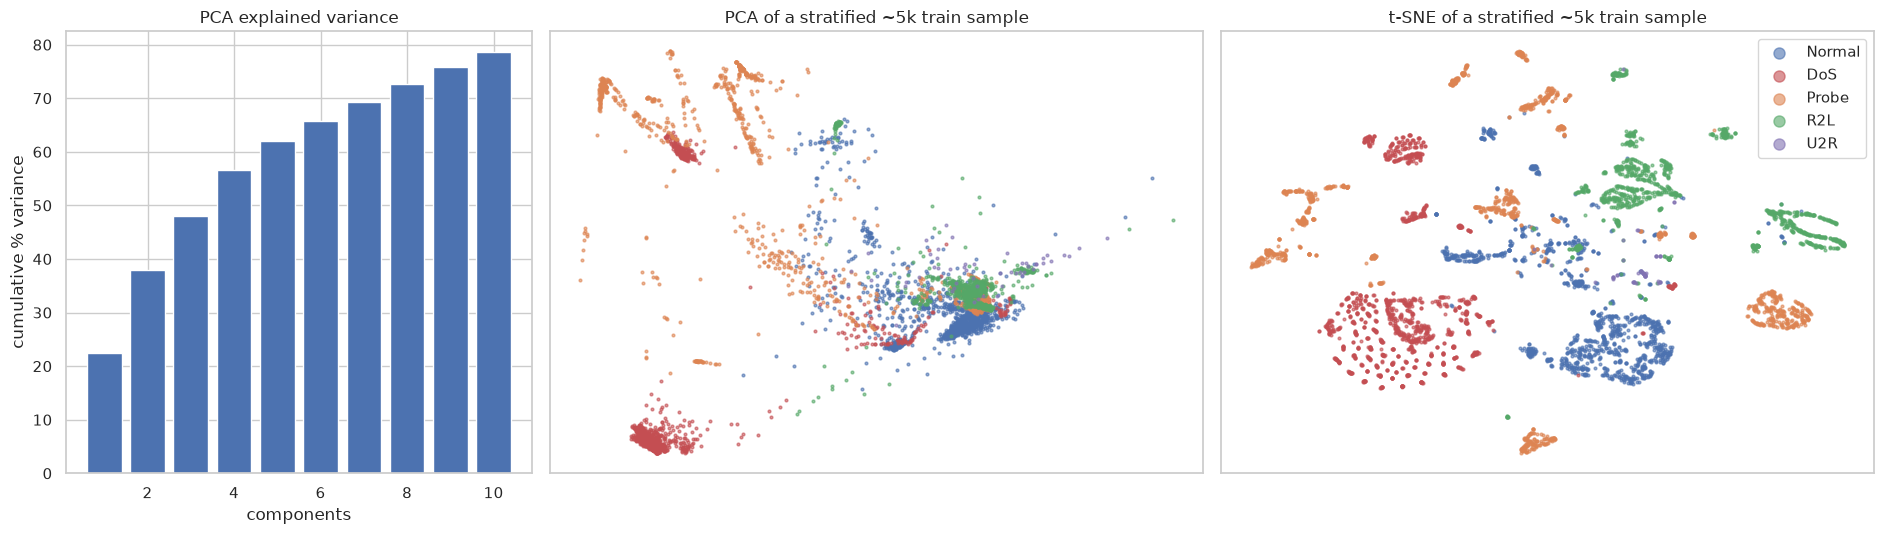

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

vis = pd.concat([d.sample(n=min(len(d), 1250), random_state=SEED)
                 for _, d in train.groupby("attack_category")])
log_cols = [c for c in num_active if not c.endswith("_rate")]
rate_cols_a = [c for c in num_active if c.endswith("_rate")]
prep = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), log_cols),
    ("rate", StandardScaler(), rate_cols_a),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
Z = prep.fit_transform(vis)  # visual-only, fit on a train sample
pca = PCA(n_components=10, random_state=SEED).fit(Z)
P = pca.transform(Z)[:, :2]
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
axes[0].bar(range(1, 11), pca.explained_variance_ratio_.cumsum() * 100, color="#4C72B0")
axes[0].set_xlabel("components"); axes[0].set_ylabel("cumulative % variance"); axes[0].set_title("PCA explained variance")
cat_pal = dict(zip(["Normal", "DoS", "Probe", "R2L", "U2R"], ["#4C72B0", "#C44E52", "#DD8452", "#55A868", "#8172B2"]))
for ax, emb, name in [(axes[1], P, "PCA"), (axes[2], T, "t-SNE")]:
    for k, colr in cat_pal.items():
        m = (vis.attack_category == k).to_numpy()
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=.6, c=colr, label=k)
    ax.set_title(f"{name} of a stratified ~5k train sample"); ax.set_xticks([]); ax.set_yticks([])
axes[2].legend(markerscale=4)
fig.tight_layout(); save(fig, "10_pca_tsne")
SUMMARY["pca_var_2"] = round(float(pca.explained_variance_ratio_[:2].sum() * 100), 1)

**Observation:**
- Several groups of features are almost duplicates (|r| > 0.95): the SYN-error rates (`serror_rate`, `srv_serror_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`), the REJ-error rates, and `num_compromised`/`num_root`.
- In t-SNE, DoS, Probe and most R2L points form clusters separate from Normal. In linear PCA space, R2L and U2R sit inside the Normal cloud.

**Interpretation:** Near-duplicate features inflate LR coefficient variance and split importance between twins in trees, without adding information. Separability is non-linear: R2L overlaps Normal linearly but not locally. This favours trees over a purely linear boundary for those families.

**Decision:** A fitted `CorrelationFilter` drops one member of each pair with |r| ≥ 0.98, learned on training folds only. PCA is not used for modelling: interpretability matters, and 10 components keep only about 78% of the variance.

## 7. Train–test distribution shift and splitting

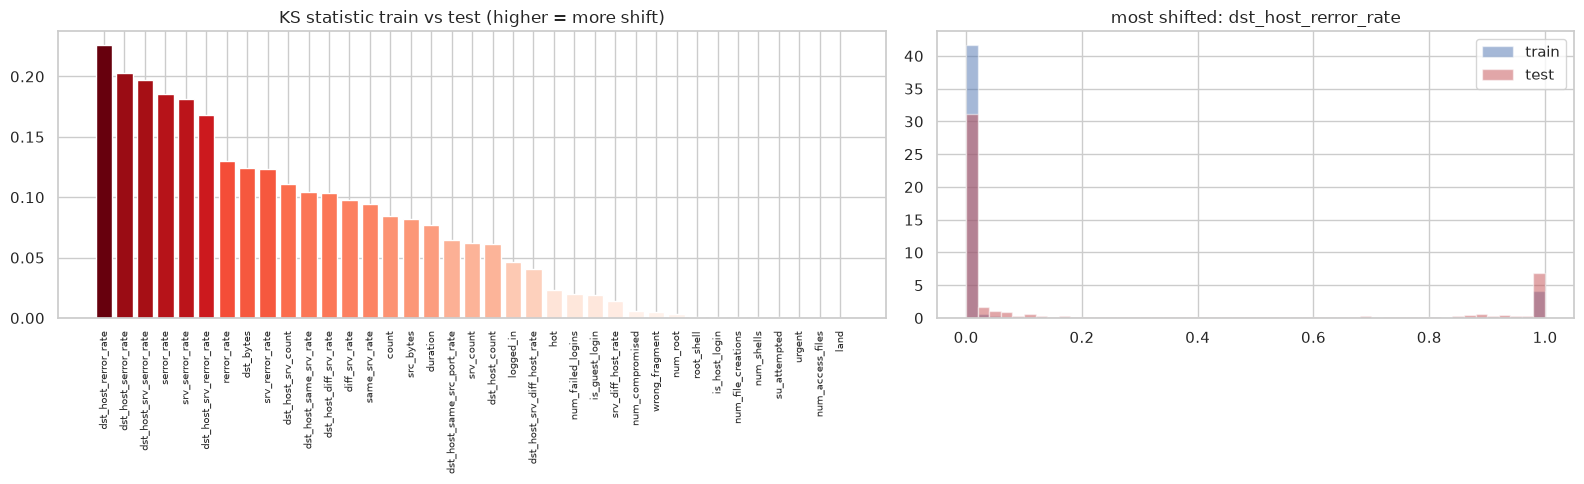

mean KS all rows: 0.072 | normal-only: 0.044


In [14]:
ks = pd.Series({c: stats.ks_2samp(train[c], test[c]).statistic for c in num_active}).sort_values(ascending=False)
SUMMARY["ks_top5"] = ks.head(5).round(3).to_dict()
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].bar(ks.index, ks.values, color=plt.cm.Reds(ks.values / ks.max()))
axes[0].tick_params(axis="x", rotation=90, labelsize=7); axes[0].set_title("KS statistic train vs test (higher = more shift)")
top = ks.index[0]
for nm, df_, col in [("train", train, "#4C72B0"), ("test", test, "#C44E52")]:
    v = df_[top] if top.endswith("_rate") else np.log1p(df_[top])
    axes[1].hist(v, bins=50, alpha=.5, density=True, color=col, label=nm)
axes[1].set_title(f"most shifted: {top}"); axes[1].legend()
fig.tight_layout(); save(fig, "11_train_test_shift")

# Shift explained by the novel attacks? Compare KS on normal traffic only.
ks_norm = pd.Series({c: stats.ks_2samp(train.loc[train.is_intrusion == 0, c], test.loc[test.is_intrusion == 0, c]).statistic
                     for c in num_active})
SUMMARY["ks_mean_all"] = round(float(ks.mean()), 3); SUMMARY["ks_mean_normal_only"] = round(float(ks_norm.mean()), 3)
print("mean KS all rows:", SUMMARY["ks_mean_all"], "| normal-only:", SUMMARY["ks_mean_normal_only"])

**Observation:**
- The largest train-vs-test shifts are in the host-level error rates tied to the attack mix: `dst_host_rerror_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`, `serror_rate`.
- Normal traffic alone shifts less (mean KS 0.044 vs 0.072 on all rows), so most covariate shift comes from the different (and novel) attack families.
- There is no timestamp, so temporal ordering cannot be checked; row order is not documented as time.
- 17 attack types exist only in `KDDTest+`.

**Interpretation:** The official split is a deliberate *generalisation* test. A random split of `KDDTrain+` measures in-distribution performance only, so validation scores will be optimistic relative to test.

**Decision:**
- Keep the official train/test split.
- Inside `KDDTrain+`, use a stratified 80/20 train/validation split and stratified 5-fold CV (seeded) for tuning, thresholds and overfitting checks.
- Look at `KDDTest+` once, for final evaluation.
- Report the validation→test gap explicitly.

## 8. EDA summary

In [15]:
decisions = pd.DataFrame([
    ("Missing / infinite values", "0 / 0", "No imputation needed"),
    ("Duplicate rows", f"{quality['dup_rows_train']} train / {quality['dup_rows_test']} test", "Nothing removed"),
    ("Constant feature", ", ".join(SUMMARY["constant"]), "Drop"),
    ("Near-constant content flags", f"{len(SUMMARY['near_constant_0.995'])} features ≥ 99.5% one value", "Keep (rare-attack signal)"),
    ("su_attempted = 2", f"{SUMMARY['su_attempted_2']['train']} train / {SUMMARY['su_attempted_2']['test']} test rows", "Map 2 → 1 (row-wise)"),
    ("Heavy-tailed counts/bytes", f"{len(heavy)} features |skew| > 2", "log1p + scale (linear only)"),
    ("Outliers", f"{SUMMARY['outlier_features_attack_enriched']}/{SUMMARY['outlier_features_total']} features: outliers attack-enriched", "Keep"),
    ("Rare service levels", f"{SUMMARY['categorical']['services_lt_50_rows']} levels < 50 rows", "OHE min_frequency=50"),
    ("Unseen test categories", "none", "handle_unknown='infrequent_if_exist'"),
    ("Highly correlated pairs", f"{len(SUMMARY['corr_pairs_gt_0.95'])} pairs |r| > 0.95", "CorrelationFilter(0.98), fit on train folds"),
    ("difficulty_level", f"univariate AUC {SUMMARY['difficulty_auc_train']}", "Exclude (leakage); evaluation slices only"),
    ("Binary prior shift", f"{SUMMARY['target']['train_attack_pct']}% → {SUMMARY['target']['test_attack_pct']}% attack", "Macro-F1/PR-AUC/recall/FPR; tune class_weight"),
    ("Novel test attacks", f"{len(SUMMARY['target']['novel_attack_types'])} types, {SUMMARY['target']['novel_rows_test']} rows", "Keep test untouched; report novel recall"),
], columns=["Finding", "Evidence", "Preprocessing decision"])

dims = pd.DataFrame({"before": [f"{len(train):,} × 41", f"{len(test):,} × 41"],
                     "after cleaning": [f"{len(train):,} × 40", f"{len(test):,} × 40"]}, index=["train", "test"])
classes = pd.DataFrame({"attack names": [train.label.nunique() - 1, test.label.nunique() - 1],
                        "categories": [train.attack_category.nunique() - 1, test.attack_category.nunique() - 1],
                        "binary classes": [2, 2]}, index=["train", "test"])
SUMMARY["dims_after_cleaning"] = {"train": [len(train), 40], "test": [len(test), 40]}
with open(OUT_DIR / "eda_summary.json", "w") as f:
    json.dump(SUMMARY, f, indent=2, default=str)
display(dims); display(classes); decisions

,before,after cleaning
train,"125,973 × 41","125,973 × 40"
test,"22,543 × 41","22,543 × 40"


,attack names,categories,binary classes
train,22,4,2
test,37,4,2


,Finding,Evidence,Preprocessing decision
0,Missing / infinite values,0 / 0,No imputation needed
1,Duplicate rows,0 train / 0 test,Nothing removed
2,Constant feature,num_outbound_cmds,Drop
3,Near-constant content flags,10 features ≥ 99.5% one value,Keep (rare-attack signal)
4,su_attempted = 2,59 train / 2 test rows,Map 2 → 1 (row-wise)
5,Heavy-tailed counts/bytes,27 features |skew| > 2,log1p + scale (linear only)
6,Outliers,11/24 features: outliers attack-enriched,Keep
7,Rare service levels,9 levels < 50 rows,OHE min_frequency=50
8,Unseen test categories,none,handle_unknown='infrequent_if_exist'
9,Highly correlated pairs,10 pairs |r| > 0.95,"CorrelationFilter(0.98), fit on train folds"


Rows are unchanged; only the constant feature is removed (41 → 40 features before encoding). The correlated-feature drop is learned inside each training fold, so its final width is reported in the preprocessing notebook. All numbers above are written to `results/eda/eda_summary.json`.